# 규제 선형 모델 - 릿지, 랏쏘, 엘라스틱넷

**규제 선형 모델의 개요**

이전까지의 선형 모델의 비용 함스
- RSS 최소화(실제 값과 예측 값의 차이를 최소화)에 포커스
- -> 변동성이 심해져 오히려 테스트 데이터 세트에서는 예측 성능 저하

==> 비용 함수는 RSS 최소화 방법과 과적합 방지를 위해 회귀 계수 값이 커지지 않도록 하는 방법이 서로 균형을 이루어야 함

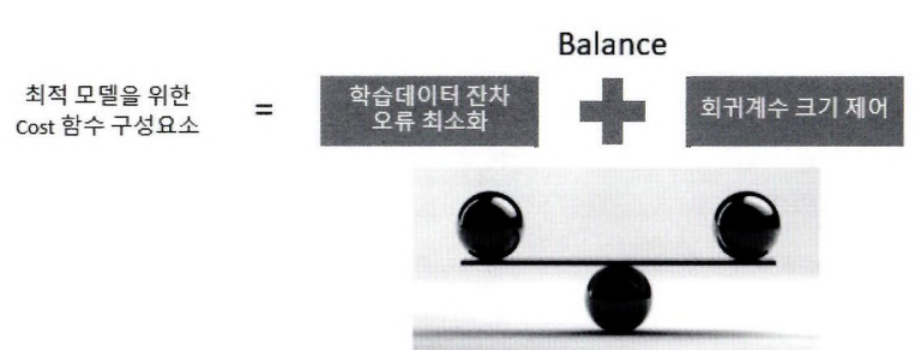

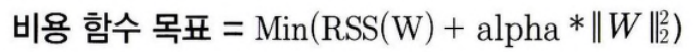

- alpha: 학습 데이터 적합 정도와 회귀 계수 값의 크기 제어를 수행하는 튜닝 파라미터

==> alpha 값을 크게 하면 비용 함수는 회귀 계수 W의 값을 작게 해 과적합을 개선할 수 있으며 alpha 값을 작게 하면 회귀 계수 W의 값이 커져도 어느 정도 상쇄가 가능하므로 학습 데이터 적합을 더 개선할 수 있다

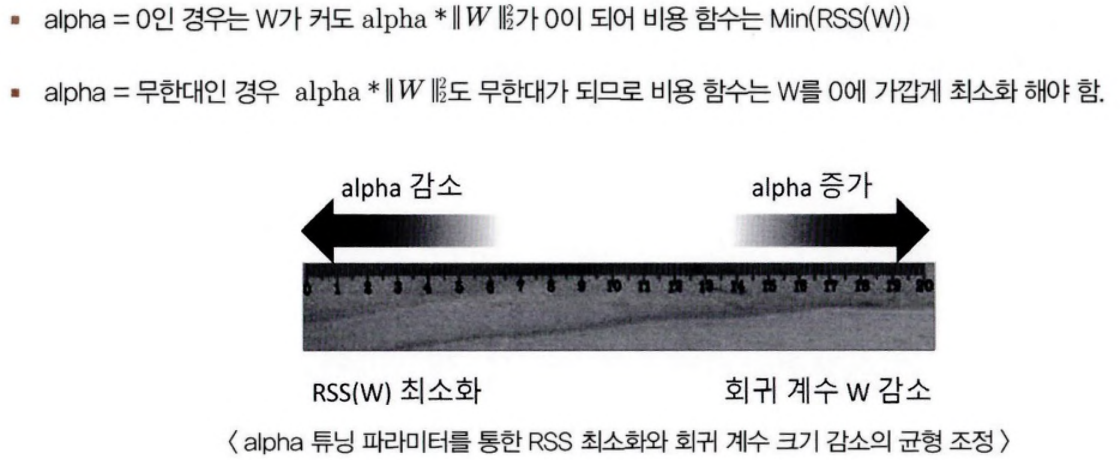

**규제(Regularization)** : 비용 함수에 alpha 값으로 페널티를 부여해 회귀 계수 값의 크기를 감소시켜 과적합을 개선하는 방식
-  L2 방식과 L1 방식
  - L2: W의 제곱에 대해 페널티를 부여하는 방식
    - L2 규제를 적용한 회귀 = 릿지(Ridge) 회귀
  - L1: W의 절댓값에 대해 페널티 부여, L1 규제를 적용하면 영향력이 크지 않은 회귀 계수 값을 0으로 변환
    - L1 규제를 적용한 회귀 = 라쏘(Lasso) 회귀

# **릿지 회귀**

Ridge 클래스를 통해 릿지 회귀를 구현
- Ridge 클래스의 주요 생성 파라미터
는 alpha이며, 이는 릿지 회귀의 alpha L2 규제 계수에 해당

In [1]:
import pandas as pd
import numpy as np

data_url = "http://lib.stat.cmu.edu/datasets/boston"
raw_df = pd.read_csv(data_url, sep=r"\s+", skiprows=22, header=None)
data = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])
target = raw_df.values[1::2, 2]

# Column names for the Boston dataset
feature_names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']

X_data = pd.DataFrame(data, columns=feature_names)
y_target = pd.Series(target, name='PRICE')

In [2]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score

# alpha=10으로 설정해 릿지 회귀 수행
ridge=Ridge(alpha=10)
neg_mse_scores=cross_val_score(ridge, X_data, y_target, scoring="neg_mean_squared_error", cv=5)
rmse_scores=np.sqrt(-1*neg_mse_scores)
avg_rmse=np.mean(rmse_scores)

print('5 folds 의 개별 Negative MSE scores：',  np.round(neg_mse_scores, 3))
print('5 folds 의 7H별 RMSE scores : ', np.round(rmse_scores, 3))
print('5 folds 의 평균 RMSE : {0:.3f} '.format(avg_rmse))


5 folds 의 개별 Negative MSE scores： [-11.422 -24.294 -28.144 -74.599 -28.517]
5 folds 의 7H별 RMSE scores :  [3.38  4.929 5.305 8.637 5.34 ]
5 folds 의 평균 RMSE : 5.518 


** 규제가 없는 LinearRegression의 RMSE 평균인 5.829보다 더 뛰어난 예측 성능을 보여준다

In [3]:
# 릿지에 사용될 alpha 파라미터의 값을 정의
alphas = [0, 0.1, 1, 10, 100]

# alphas list 값을 반복하면서 alpha에 따른 평균 rmse를 구함.
for alpha in alphas:
  ridge=Ridge(alpha=alpha)

  # cross_val_scores르 이용해 5 폴드의 평균 RMSE를 계산
  neg_mse_scores=cross_val_score(ridge, X_data, y_target, scoring="neg_mean_squared_error", cv=5)
  avg_rmse=np.mean(np.sort(-1*neg_mse_scores))
  print('alpha {0} 일 때 5 folds의 평균 RMSE : {1:.3f}'.format(alpha, avg_rmse))

alpha 0 일 때 5 folds의 평균 RMSE : 37.132
alpha 0.1 일 때 5 folds의 평균 RMSE : 36.707
alpha 1 일 때 5 folds의 평균 RMSE : 35.267
alpha 10 일 때 5 folds의 평균 RMSE : 33.395
alpha 100 일 때 5 folds의 평균 RMSE : 29.906


** alpha가 100일 때 평균 RMSE가 5.330으로 가장 좋다

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

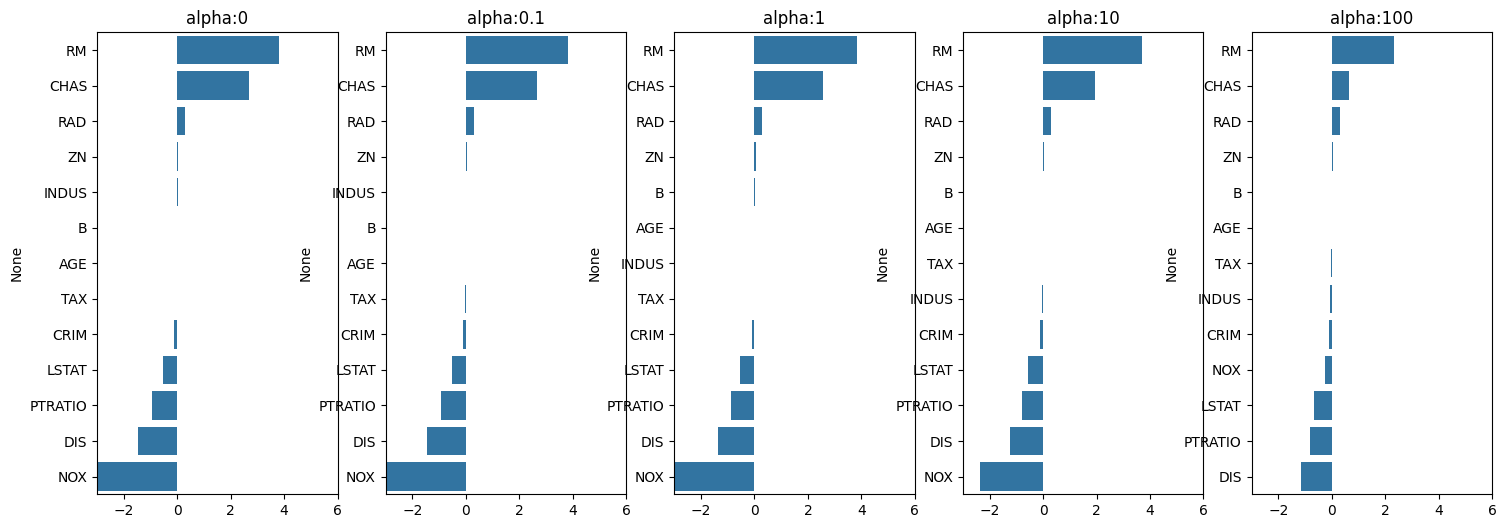

In [5]:
# 각 alpha에 따른 회귀 계수 값을 시각화하기 위해 5개의 열로 된 맷플롯립 축 생성
fig, axs = plt.subplots(figsize=(18, 6), nrows=1, ncols=5)

# 각 alpha에 따른 회귀 계수 값을 데이터로 저장하기 위한 DataFrame 생성
coeff_df = pd.DataFrame()

# alphas 리스트 값을 차례로 입력해 회귀 계수 값 시각화 및 데이터 저장. pos는 axis의 위치 지정
for pos, alpha in enumerate(alphas):
  ridge = Ridge(alpha = alpha)
  ridge.fit(X_data, y_target)

  # alpha에 따른 피처별로 회귀 계수를 Series로 변환하고 이를 DataFrame의 칼럼으로 추가
  coeff=pd.Series(data=ridge.coef_, index=X_data.columns )
  colname='alpha:'+str(alpha)
  coeff_df[colname] = coeff

  # 막대 그래프로 각 alpha 값에서의 회귀 계수를 시각화. 회귀 계수값이 높은 순으로 표현
  coeff = coeff.sort_values(ascending=False)
  axs[pos].set_title(colname)
  axs[pos].set_xlim(-3, 6)
  sns.barplot(x=coeff.values, y=coeff.index, ax=axs[pos])

# for 문 바깥에서 맷플롯립의 show 호출 및 alpha에 따른 피처별 회귀 계수를 DataFrame으로 표시
plt.show()

** alpha 값을 계속 증가시킬수록 회귀 계수 값은 지속적으로 작아짐을 알 수 있다

In [6]:
ridge_alphas = [0, 0.1, 1, 10, 100]
sort_column = 'alpha:'+str(ridge_alphas[0])
coeff_df.sort_values(by=sort_column, ascending=False)

,alpha:0,alpha:0.1,alpha:1,alpha:10,alpha:100
RM,3.809865,3.818233,3.854000,3.702272,2.334536
CHAS,2.686734,2.670019,2.552393,1.952021,0.638335
RAD,0.306049,0.303515,0.290142,0.279596,0.315358
ZN,0.046420,0.046572,0.047443,0.049579,0.054496
INDUS,0.020559,0.015999,-0.008805,-0.042962,-0.052826
B,0.009312,0.009368,0.009673,0.010037,0.009393
AGE,0.000692,-0.000269,-0.005415,-0.010707,0.001212
TAX,-0.012335,-0.012421,-0.012912,-0.013993,-0.015856
CRIM,-0.108011,-0.107474,-0.104595,-0.101435,-0.102202
LSTAT,-0.524758,-0.525966,-0.533343,-0.559366,-0.660764


** alpha 값이 증가하면서 회귀 계수가 지속적으로 작아지고 있음을 알 수 있습니다. 하지만 릿지 회귀의
경우에는 회귀 계수를 0으로 만들지는 않는다

# **라쏘 회귀**

라쏘 회귀: W의 절댓값에 페널티를 부여하는 L1 규제를 선형 회귀에 적용
- L2 규제가 회귀 계수의 크기를 감소시키는 데 반해, L1 규제는 불필요한 회귀 계수를 급격하게 감소시켜 0으로 만들고 제거한다
  - 이러한 측면에서 L1 규제는 적절한 피처만 회귀에 포함시키는 피처 선택의 특성을 가지고 있다

In [9]:
from sklearn.linear_model import Lasso, ElasticNet

# alpha값에 따른 회귀 모델의 폴드 평균 RMSE를 출력하고 회귀 계수값들을 DataFrame으로 반환
def get_linear_reg_eval(model_name, params=None, X_data_n=None, y_target_n=None,
                        verbose=True, return_coeff=True):
  coeff_df = pd.DataFrame()
  if verbose : print('#######', model_name , '#######')
  for param in params:
    if model_name =='Ridge': model = Ridge(alpha=param)
    elif model_name =='Lasso': model = Lasso(alpha=param)
    elif model_name =='ElasticNet': model = ElasticNet(alpha=param, l1_ratio=0.7)
    neg_mse_scores = cross_val_score(model, X_data_n,
                                     y_target_n, scoring="neg_mean_squared_error", cv = 5)
    avg_rmse = np.mean(np.sqrt(-1 * neg_mse_scores))
    print('alpha {0}일 때 5 폴드 세트의 평균 RMSE: {1:.3f}'.format(param, avg_rmse))

    # cross_val_score는 evaluation metric만 반환하므로 모델을 다시 학습하여 회귀 계수 추출
    model.fit(X_data_n , y_target_n)
    if return_coeff:
      # alpha에 따른 피처별 회귀 계수를 Series로 변환하고 이를 DataFrame의 칼럼으로 추가.
      coeff = pd.Series(data=model.coef_ , index=X_data_n.columns )
      colname='alpha:'+str(param)
      coeff_df[colname] = coeff

  return coeff_df
# end of get_linear_reg_eval

In [10]:
# 라쏘에 사용될 alpha 파라미터의 값을 정의하고 get_linear_reg_eval() 함수 호출
lasso_alphas = [ 0.07, 0.1, 0.5, 1, 3]
coeff_lasso_df =get_linear_reg_eval('Lasso', params=lasso_alphas, X_data_n=X_data, y_target_n=y_target)

####### Lasso #######
alpha 0.07일 때 5 폴드 세트의 평균 RMSE: 5.612
alpha 0.1일 때 5 폴드 세트의 평균 RMSE: 5.615
alpha 0.5일 때 5 폴드 세트의 평균 RMSE: 5.669
alpha 1일 때 5 폴드 세트의 평균 RMSE: 5.776
alpha 3일 때 5 폴드 세트의 평균 RMSE: 6.189


** alpha가 0.07일 때 5.612로 가장 좋은 평균 RMSE를 보여준다

In [12]:
# 반환된 coeff_lasso_df를 첫 번째 칼럼순으로 내림차순 정렬해 회귀계수 DataFrame 출력
sort_column = 'alpha:'+str(lasso_alphas[0])
coeff_lasso_df.sort_values(by=sort_column, ascending=False)

,alpha:0.07,alpha:0.1,alpha:0.5,alpha:1,alpha:3
RM,3.789725,3.703202,2.498212,0.949811,0.000000
CHAS,1.434343,0.955190,0.000000,0.000000,0.000000
RAD,0.270936,0.274707,0.277451,0.264206,0.061864
ZN,0.049059,0.049211,0.049544,0.049165,0.037231
B,0.010248,0.010249,0.009469,0.008247,0.006510
NOX,-0.000000,-0.000000,-0.000000,-0.000000,0.000000
AGE,-0.011706,-0.010037,0.003604,0.020910,0.042495
TAX,-0.014290,-0.014570,-0.015442,-0.015212,-0.008602
INDUS,-0.042120,-0.036619,-0.005253,-0.000000,-0.000000
CRIM,-0.098193,-0.097894,-0.083289,-0.063437,-0.000000


# **엘라스틱넷 회귀**

엘라스틱넷(Elastic Net) 회귀는 L2 규제와 L1 규제를 결합한 회귀
- 라쏘 회귀가 서로 상관관계가 높은 피처들의 경우에
이들 중에서 중요 피처만을 셀렉션하고 다른 피처들은 모두 회귀 계수를 0으로 만드는 성향이 강하다
  - 특히 이러한 성향으로 인해 alpha값에 따라 회귀 계수의 값이 급격히 변동할 수도 있는데, 엘라스틱넷 회귀는 이를 완화하기 위해 L2 규제를 라쏘 회귀에 추가한 것
- 단점은 L1과 L2 규제가 결합된 규제로 인해 수행시간이 상대적으로 오래 걸린다는 것

In [13]:
# 엘라스틱넷에 사용될 alpha 파라미터의 값들을 정의하고 get_linear_reg_eval() 함수 호출
# I1_ratio는 0.7로 고정
elastic_alphas = [ 0.07, 0.1, 0.5, 1, 3]
coeff_elastic_df =get_linear_reg_eval('ElasticNet', params=elastic_alphas,
                                      X_data_n=X_data, y_target_n=y_target)


####### ElasticNet #######
alpha 0.07일 때 5 폴드 세트의 평균 RMSE: 5.542
alpha 0.1일 때 5 폴드 세트의 평균 RMSE: 5.526
alpha 0.5일 때 5 폴드 세트의 평균 RMSE: 5.467
alpha 1일 때 5 폴드 세트의 평균 RMSE: 5.597
alpha 3일 때 5 폴드 세트의 평균 RMSE: 6.068


In [14]:
# 반환된 coeff_elastic_df를 첫 번째 칼럼순으로 내림차순 정렬해 회귀계수 DataFrame 출력
sort_column='alpha:'+str(elastic_alphas[0])
coeff_elastic_df.sort_values(by=sort_column, ascending=False)

,alpha:0.07,alpha:0.1,alpha:0.5,alpha:1,alpha:3
RM,3.574162,3.414154,1.918419,0.938789,0.000000
CHAS,1.330724,0.979706,0.000000,0.000000,0.000000
RAD,0.278880,0.283443,0.300761,0.289299,0.146846
ZN,0.050107,0.050617,0.052878,0.052136,0.038268
B,0.010122,0.010067,0.009114,0.008320,0.007020
AGE,-0.010116,-0.008276,0.007760,0.020348,0.043446
TAX,-0.014522,-0.014814,-0.016046,-0.016218,-0.011417
INDUS,-0.044855,-0.042719,-0.023252,-0.000000,-0.000000
CRIM,-0.099468,-0.099213,-0.089070,-0.073577,-0.019058
NOX,-0.175072,-0.000000,-0.000000,-0.000000,-0.000000


** alpha 0.5일 때 RMSE가 5.467로 가장 좋은 예측 성능을 보이고 있다

** alpha값에 따른 피처들의
회귀 계수들 값이 라쏘보다는 상대적으로 0이 되는 값이 적음을 알 수 있다

# **선형 회귀 모델을 위한 데이터 변환**

<사이킷런을 이용해 피처 데이터 세트에 적용하는 변환 작업>

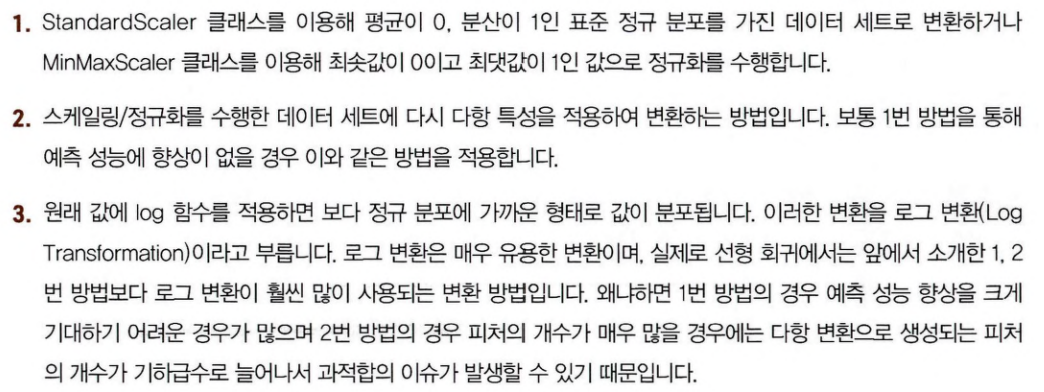

In [15]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, PolynomialFeatures

# method는 표준 정규 분포 변환(Standard), 최댓값/최솟값 정규화(MinMax), 로그변환(Log) 결정
# p_degree는 다항식 특성을 추가할 때 적용. p_degree는 2 이상 부여하지 않음.
def get_scaled_data(method='None', p_degree=None, input_data=None):
  if method=='Standard':
    scaled_data = StandardScaler().fit_transform(input_data)
  elif method == 'MinMax':
    scaled_data = MinMaxScaler().fit_transform(input_data)
  elif method == 'Log' :
    scaled_data = np.log1p(input_data)
  else:
    scaled_data = input_data

  if p_degree != None:
    scaled_data = PolynomialFeatures(degree=p_degree,
                                     include_bias=False).fit_transform(scaled_data)

  return scaled_data



In [16]:
# Ridge의 alpha값을 다르게 적용하고 다양한 데이터 변환 방법에 따른 RMSE 추출.
alphas = [0.1, 1, 10, 100]

# 5개 방식으로 변환. 먼저 원본 그대로, 표준정규 분포, 표준정규 분포+다항식 특성
# 최대/최소 정규화, 최대/최소 정규화+다항식 특성, 로그변환
scale_methods=[(None, None), ('Standard', None), ('Standard', 2),
('MinMax', None), ('MinMax', 2), ('Log', None)]
for scale_method in scale_methods:
  X_data_scaled = get_scaled_data(method=scale_method[0], p_degree=scale_method[1],
                                  input_data=X_data)
print('## 변환 유형:{0}, Polynomial Degree：{1}'.format(scale_method[0], scale_method[1]))
get_linear_reg_eval('Ridge', params=alphas, X_data_n=X_data_scaled,
                    y_target_n=y_target, verbose=False, return_coeff=False)

## 변환 유형:Log, Polynomial Degree：None
alpha 0.1일 때 5 폴드 세트의 평균 RMSE: 4.770
alpha 1일 때 5 폴드 세트의 평균 RMSE: 4.676
alpha 10일 때 5 폴드 세트의 평균 RMSE: 4.836
alpha 100일 때 5 폴드 세트의 평균 RMSE: 6.241


""


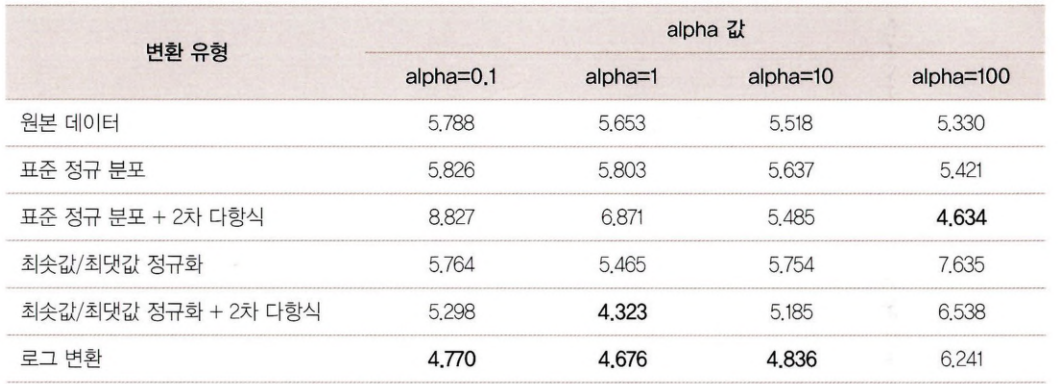

결과를 보면 표준 정규 분포와 최솟값/최댓값 정규화로 피처 데이터 세트를 변경해도 성능상의 개선은 없다
- 표준 정규 분포로 일차 변환 후 2차 다항식 변환을 했을 때 alpha=100에서 4.634로 성능이 개선됐으며 최솟값/최댓값 정규화로 일차 변환 후 2차 다항식 변한을 했을 때 alpha=l에서 4.323으로 성능이 개선됐다
- 피처의 개수가 많을 경우 적용하기 힘들며, 또한 데이터 건수가 많아지면 계산에 많은 시간이 소모되어 적용에 한계가 있다

# 로지스틱 회귀

로지스틱 회귀는 선형 회귀 방식을 분류에 적용한 알고리즘
- 분류에 사용
- 회귀가 선형인가 비선형인가는독립변수가 아닌 가중
X](weight) 변수가 선형인지 아닌지를 따른다
- 시그모이드(Sigmoid) 함수 최적선을 찾고 이 시그모이드 함수의 반환 값을 확률로 간주해 확률에 따라 분류를 결정

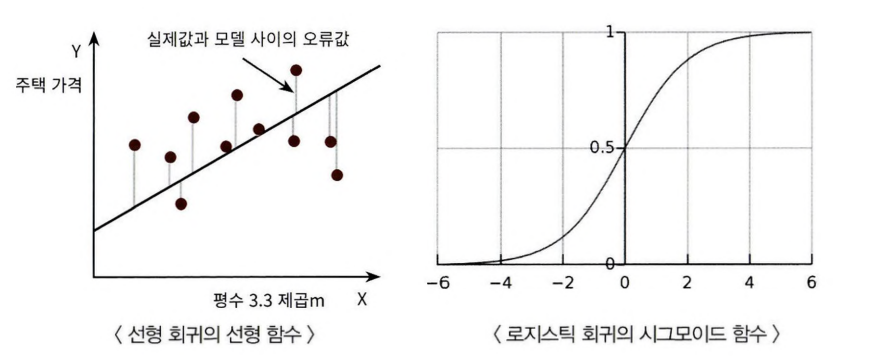

많은 자연, 사회 현상에서 특정 변수의 확률 값은 선형이 아니라 위의 시그모이드 함수와 같이 S자 커
브 형태를 가진다
- 시그모이드 함수는 x 값이 十, -로 아무리 커지거나 작아져도 y 값은 항상 0과 1 사이 값을 반환한다
  - x 값이 커지면 1에 근사하며 x 값이 작아지면 0에 근사한다
  - x가 0일 때는 0.5

[회귀 문제를 분류 문제에 적용]
- 종양의 크기에 따라 악성 종양인지(Yes = 1) 그렇지
않은지(No=0)를 회귀를 이용해 1과 0의 값으로 예측하는 것
- 종양 크기에 따라 악성이 될 확률
이 높다고 한다면 다음 그림의 왼쪽과 같이 종양 크기를 X축, 악성 종양 여부를 Y 축에 표시할 때 데이
터 분포가 그림과 같이 될 수 있으며, 이에 회귀를 적용하면 데이터가 모여 있는 곳으로 선형 회귀 선을
그릴 수 있다
- 하지만 이 회귀 라인은 0과 1을 제대로 분류하지 못하고 있다(선형 회귀가 분류를 못하는 건 아니지만 정확도가 떨어진다)
- 하지만 오른쪽 그림과 같이 S자 커브 형태의 시그모이드 함수를 이용하면 좀 더 정확하게 0과 1에 대해 분류를 할 수 있음을 알 수 있다

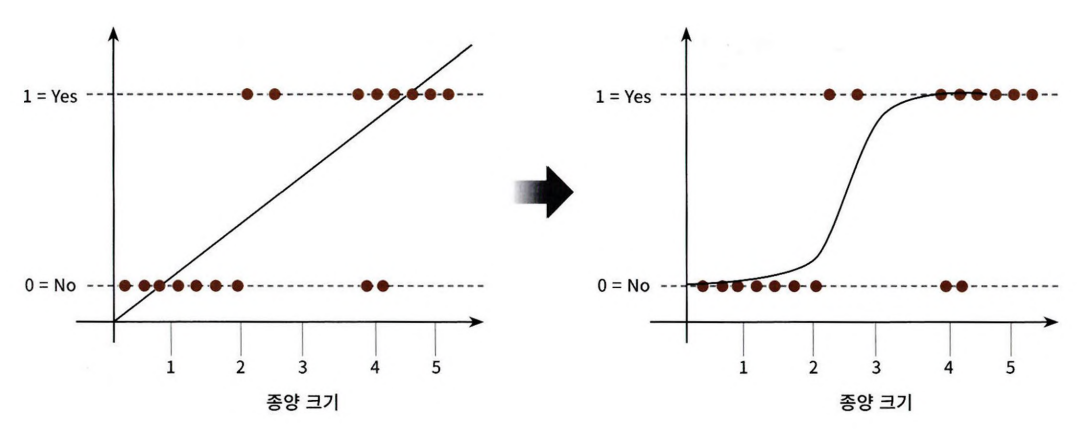

LogisticRegression 클래스의 회귀 계수 최적화는 경사 하강법 외에 다양한 최적화 방안을 선택할 수 있다
- LogisticRegression 클래스에서 solver 파라미터의 ‘Ibfgs’, ‘liblineaf,‘newton-eg’, ‘sag’, ‘saga’ 값을 적용해서 최적화를 선택할 수 있다


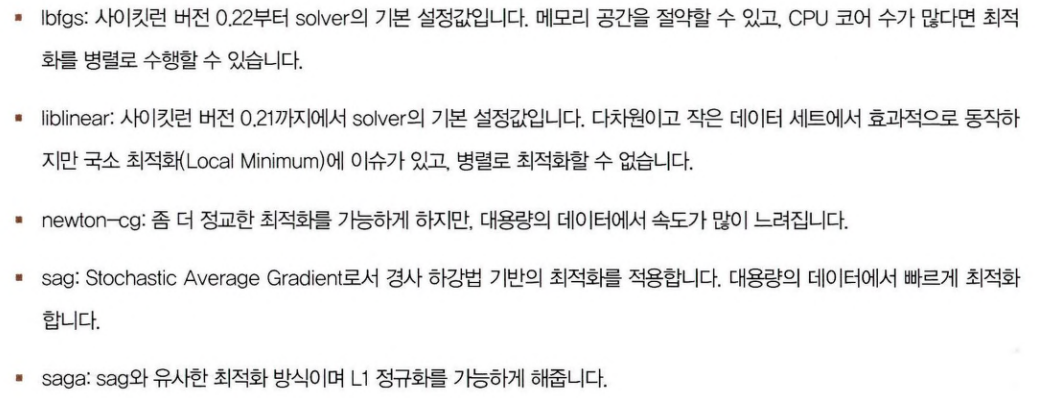

<LogisticRegression 클래스를 이용하여 위스콘신 유방암 데이터 세트 기반에서 로지
스틱 회귀로 암 여부를 판단>

In [17]:
import pandas as pd
import matplotlib.pyplot as pit
%matplotlib inline
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
cancer = load_breast_cancer()

In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score

# 로지스틱 회귀를 위해 피처 데이터 세트 스케일링
scaler = StandardScaler()
data_scaled = scaler.fit_transform(cancer.data)

# 학습 및 테스트 데이터 세트로 분할
X_train, X_test, y_train, y_test = train_test_split(data_scaled, cancer.target, test_size=0.3, random_state=0)

# 로지스틱 회귀를 이용하여 학습 및 예측 수행.
# solver 인자값을 생성자로 입력하지 않으면 solver='lbfgs'
lr_clf = LogisticRegression()
lr_clf.fit(X_train, y_train)
lr_preds = lr_clf.predict(X_test)
lr_preds_proba = lr_clf.predict_proba(X_test)[:, 1]

# accuracy와 roc_auc 측정
print('accuracy： {0:.3f}, roc_auc：{1:.3f}'.format(accuracy_score(y_test, lr_preds),
                                                  roc_auc_score(y_test, lr_preds_proba)))

accuracy： 0.977, roc_auc：0.995


In [21]:
solvers = ['lbfgs', 'liblinear', 'newton-cg', 'sag', 'saga']
# 여러 개의 solver 값별로 LogisticRegression 학습 후 성능 평가
for solver in solvers:
    lr_clf = LogisticRegression(solver=solver, max_iter=600)
    lr_clf.fit(X_train, y_train)
    lr_preds = lr_clf.predict(X_test)
    lr_preds_proba = lr_clf.predict_proba(X_test)[:, 1]
    # accuracy와 roc_auc 측정
    print('solver: {0}, accuracy: {1:.3f}, roc_auc: {2:.3f}'.format(
        solver,
        accuracy_score(y_test, lr_preds),
        roc_auc_score(y_test, lr_preds_proba)
    ))

solver: lbfgs, accuracy: 0.977, roc_auc: 0.995
solver: liblinear, accuracy: 0.982, roc_auc: 0.995
solver: newton-cg, accuracy: 0.977, roc_auc: 0.995
solver: sag, accuracy: 0.982, roc_auc: 0.995
solver: saga, accuracy: 0.982, roc_auc: 0.995


** liblinear와 sag, saga일 경우에 정확도가 0.982, ROC—AUC가 0.995로 Ibfgs나 newton-cg 대비하여 상대적인 성능 수치가 약간 높다
- 다만, 데이터 세트가 워낙 작기 때문에 개별 solver별 성능 결과의 차이는 크게 의미 있는 결과는 아니다


Solver와 maxjter 외에 사이킷런 LogisticRegression 클래스의 주요 하이퍼 파라미터로 penalty와
으가 있다
- penalty는 규제(Regularization)의 유형을 설정하며 ‘12’로 설정 시 L2 규제를,‘11’으로
설정 시 L1 규제를 뜻한다
- 기본은 ‘12, C는 규제 강도를 조절하는 alpha 값의 역수 즉 C = 1/alpha이다
  - C 값이 작을수록 규제 강도가 크다

In [23]:
from sklearn.model_selection import GridSearchCV

# 하이퍼 파라미터 딕셔너리의 오타 및 기호 수정
params = {
    'solver': ['liblinear', 'lbfgs'],
    'penalty': ['l1', 'l2'],
    'C': [0.01, 0.1, 1, 5, 10]
}

lr_clf = LogisticRegression()

# scoring과 cv 파라미터의 문자열 닫기 및 구분 기호 수정
grid_clf = GridSearchCV(lr_clf, param_grid=params, scoring='accuracy', cv=3)
grid_clf.fit(data_scaled, cancer.target)

# 포맷팅 문자열 내 비표준 전각 콜론 및 기호 수정
print('최적 하이퍼 파라미터: {0}, 최적 평균 정확도: {1:.3f}'.format(
    grid_clf.best_params_,
    grid_clf.best_score_
))

최적 하이퍼 파라미터: {'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}, 최적 평균 정확도: 0.979


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
15 fits failed out of a total of 60.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
15 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py", line 1193, in fit
    solver = _check_solver

** solver가 liblinear Penalty가 L2 규제, C 값은 0.1 일 때, 평균 정확도가 0.979로 가장 좋은 성능을 나
타냈다

로지스틱 회귀
- 가볍고 빠르지만, 이진 분류 예측 성능도 뛰어나다
  - 이진 분류의 기본 모델로 사용하는 경우가 많다
- 희소한 데이터 세트 분류에도 뛰어난 성능을 보여서 텍스트 분류에서도 자주 사용


# 회귀 트리

회귀 함수를 기반으로 하지 않고 결정 트리와 같이 트리를 기반으로 하는 회귀 방식 = 회귀 트리 이용
- 회귀를 위한 트리를 생성하고 이를 기반으로
회귀 예측을 하는 것
- 리프 노드에 속한 데이터 값의 평균값을 구해 회귀 예측값을 계산

<간단한 데이터 세트를 이용해 회귀 트리가 Y I
어떻게 동작하는지 살펴보기>

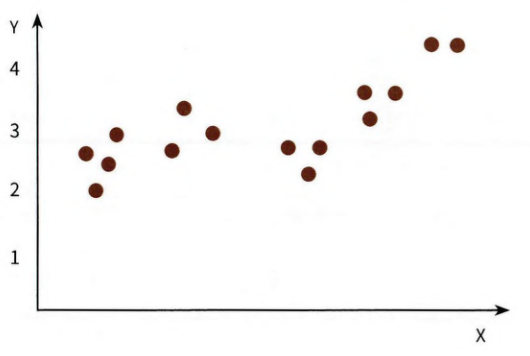

이 데이터 세트의 X 피처를 결정 트리 기반으로 분할하면 X값의 균일도를 반영한 지니 계수에 따라 다
음 그림의 왼쪽과 같이 분할할 수 있다
- 루트 노드를 Split 0 기준으로 분할하고 이렇게 분할된 규칙 노드에서 다시 Split 1과 Split 2 규칙 노드로 분할할 수 있다
- 그리고 Split 2는 다시 재귀적으로 Split 3 규칙 노드로 다음 그림의 오른쪽과 같이 트리 규칙으로 변환될 수 있다

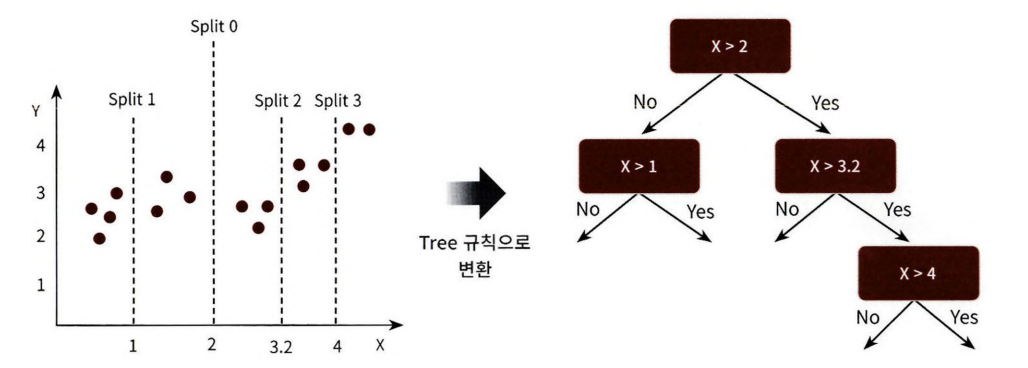

리프 노드 생성 기준에 부합하는 트리 분할이 완료됐다면 리프 노드에 소속된 데이터 값의 평균값을 구해서 최종적으로 리프 노드에 결정 값으로 할당한다

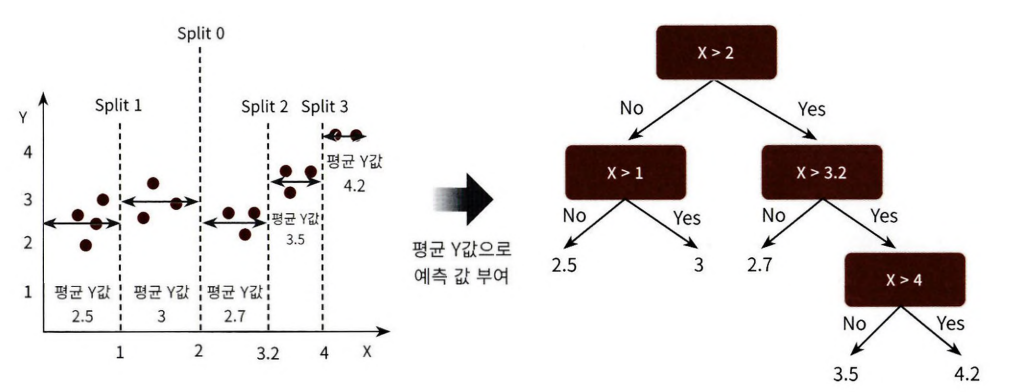

[사이킷런의 트리 기반 회귀와 분류의 Estimator 클래스]

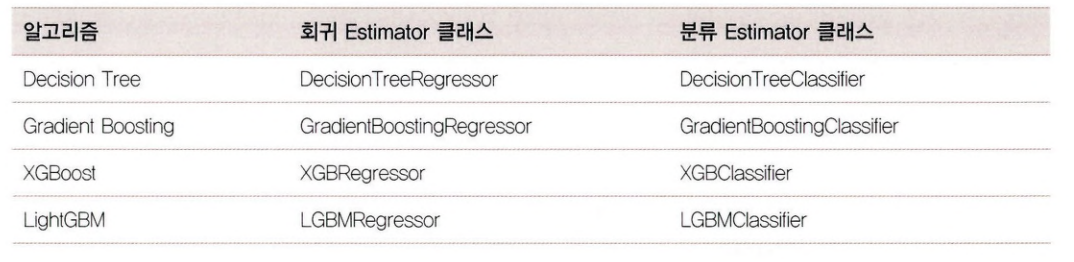

[사이킷런의 랜덤 포레스트 회귀 트리인 RandomForestRegressor를 이용해 앞의 선형 회귀에서 다룬 보스턴 주택 가격 예측을 수행]

In [31]:
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestRegressor
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Load the boston dataset from the original source
data_url = "http://lib.stat.cmu.edu/datasets/boston"
raw_df = pd.read_csv(data_url, sep=r"\s+", skiprows=22, header=None)
data = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])
target = raw_df.values[1::2, 2]
X_data = pd.DataFrame(data)
y_target = pd.Series(target, name='PRICE')

# 랜덤 포레스트 모델 설정 (random_state=0, n_estimators=1000)
rf = RandomForestRegressor(random_state=0, n_estimators=1000)

# 교차 검증 수행
neg_mse_scores = cross_val_score(rf, X_data, y_target, scoring="neg_mean_squared_error", cv = 5)
rmse_scores = np.sqrt(-1 * neg_mse_scores)
avg_rmse = np.mean(rmse_scores)

# 결과 출력
print('5 교차 검증의 개별 Negative MSE scores:', np.round(neg_mse_scores, 2))
print('5 교차 검증의 개별 RMSE scores:', np.round(rmse_scores, 2))
print('5 교차 검증의 평균 RMSE : {0:.3f}'.format(avg_rmse))

5 교차 검증의 개별 Negative MSE scores: [ -7.88 -13.14 -20.57 -46.23 -18.88]
5 교차 검증의 개별 RMSE scores: [2.81 3.63 4.54 6.8  4.34]
5 교차 검증의 평균 RMSE : 4.423


In [32]:
def get_model_cv_prediction(model, X_data, y_target):
    neg_mse_scores = cross_val_score(model, X_data, y_target, scoring="neg_mean_squared_error", cv = 5)
    rmse_scores = np.sqrt(-1 * neg_mse_scores)
    avg_rmse = np.mean(rmse_scores)
    print('#####', model.__class__.__name__, ' #####')
    print(' 5 교차 검증의 평균 RMSE : {0:.3f} '.format(avg_rmse))

In [33]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

dt_reg = DecisionTreeRegressor(random_state=0, max_depth=4)
rf_reg = RandomForestRegressor(random_state=0, n_estimators=1000)
gb_reg = GradientBoostingRegressor(random_state=0, n_estimators=1000)
xgb_reg = XGBRegressor(n_estimators=1000)
lgb_reg = LGBMRegressor(n_estimators=1000)

# 트리 기반의 회귀 모델을 반복하면서 평가 수행
models = [dt_reg, rf_reg, gb_reg, xgb_reg, lgb_reg]
for model in models:
    get_model_cv_prediction(model, X_data, y_target)

스트리밍 출력 내용이 길어서 마지막 5000줄이 삭제되었습니다.
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best 

feature_importances_를 이용해 피처별 중요도를 알 수 있다

<Axes: xlabel='None', ylabel='None'>

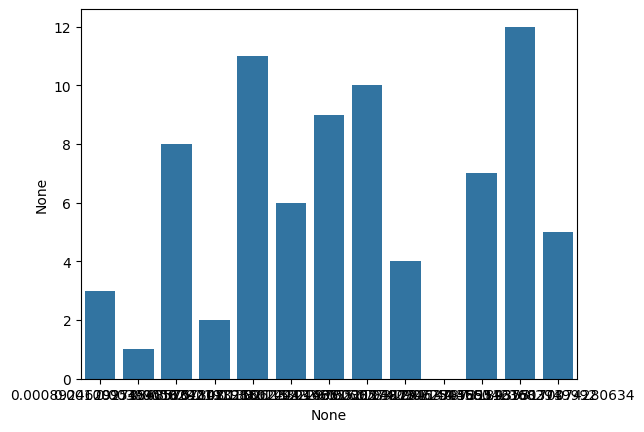

In [34]:
import seaborn as sns
%matplotlib inline
rf_reg = RandomForestRegressor(n_estimators=1000)

# 앞 예제에서 만들어진 X.data, y_target 데이터 세트를 적용해 학습합니다.
rf_reg.fit(X_data, y_target)
feature_series = pd.Series(data=rf_reg.feature_importances_, index=X_data.columns )
feature_series = feature_series.sort_values(ascending=False)
sns.barplot(x= feature_series, y=feature_series.index)


[회귀 트리 Regressor가 어떻게 예측값을 판단하는지 선형 회귀와 비교해 시각화]

(100, 2)


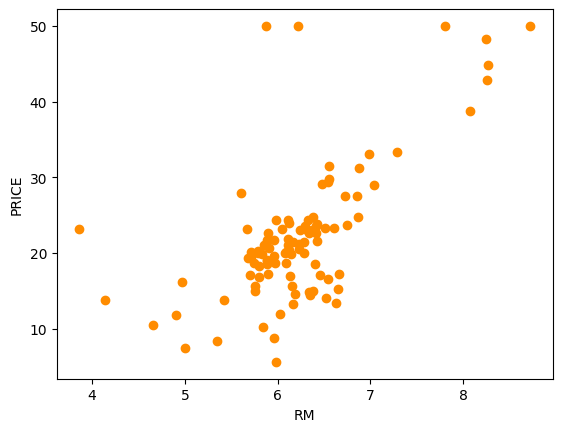

In [37]:
import matplotlib.pyplot as plt

# feature_names가 정의되어 있다면 적용하고, 없다면 직접 지정
feature_names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']
X_data.columns = feature_names

# X_data와 y_target을 병합하여 시각화에 사용할 샘플 데이터프레임 생성
bostonDF = pd.concat([X_data, y_target], axis=1)

# RM 피처와 PRICE 피처만 선택하여 100개 샘플링
bostonDF_sample = bostonDF[['RM', 'PRICE']]
bostonDF_sample = bostonDF_sample.sample(n=100, random_state=0)
print(bostonDF_sample.shape)

# 산점도 시각화
plt.figure()
plt.scatter(bostonDF_sample.RM, bostonDF_sample.PRICE, c="darkorange")
plt.xlabel('RM')
plt.ylabel('PRICE')
plt.show()

In [39]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

# 선형 회귀와 결정 트리 기반의 Regressor 생성. DecisionTreeRegressor의 max_depth는 각각 2, 7
lr_reg = LinearRegression()
rf_reg2 = DecisionTreeRegressor(max_depth=2)
rf_reg7 = DecisionTreeRegressor(max_depth=7)

# 실제 예측을 적용할 테스트용 데이터 세트를 4.5~8.5까지의 100개 데이터 세트로 생성.
X_test = np.arange(4.5, 8.5, 0.04).reshape(-1, 1)

# 보스턴 주택 가격 데이터에서 시각화를 위해 피처(RM)와 타겟(PRICE) 추출
X_feature = bostonDF_sample['RM'].values.reshape(-1, 1)
y_target = bostonDF_sample['PRICE'].values.reshape(-1, 1)

# 학습과 예측 수행.
lr_reg.fit(X_feature, y_target)
rf_reg2.fit(X_feature, y_target)
rf_reg7.fit(X_feature, y_target)

pred_lr = lr_reg.predict(X_test)
pred_rf2 = rf_reg2.predict(X_test)
pred_rf7 = rf_reg7.predict(X_test)

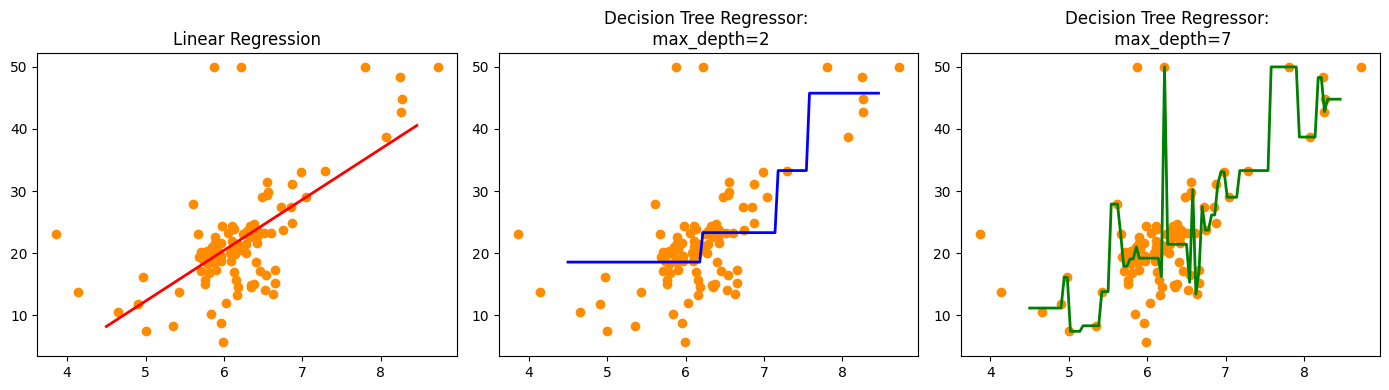

In [45]:
fig, (ax1, ax2, ax3) = plt.subplots(figsize=(14, 4), ncols=3)

# 선형 회귀 예측 시각화
ax1.set_title('Linear Regression')
ax1.scatter(bostonDF_sample.RM, bostonDF_sample.PRICE, c="darkorange")
ax1.plot(X_test, pred_lr, label="linear", linewidth=2, c="red")

# DecisionTreeRegressor(max_depth=2) 예측 시각화
ax2.set_title('Decision Tree Regressor: \n max_depth=2')
ax2.scatter(bostonDF_sample.RM, bostonDF_sample.PRICE, c="darkorange")
ax2.plot(X_test, pred_rf2, label="max_depth: 2", linewidth=2, c="blue")

# DecisionTreeRegressor(max_depth=7) 예측 시각화
ax3.set_title('Decision Tree Regressor: \n max_depth=7')
ax3.scatter(bostonDF_sample.RM, bostonDF_sample.PRICE, c="darkorange")
ax3.plot(X_test, pred_rf7, label="max_depth: 7", linewidth=2, c="green")

plt.tight_layout()
plt.show()